# **ST1519 Agile MLOps CA1 — SP-buy Fraud Detection**

## **1. Problem Statement**

SP-buy is an e-commerce platform with users across several countries. Some users place orders and then seek refunds without proper reasons, causing losses to vendors and the platform.

The objective of this project is to build a machine learning model that predicts whether an order is **fraud** based on customer and order information.

---

## **2. Plan**

The following approach was implemented:

- Load and inspect the historical datasets
- Perform exploratory data analysis to identify data quality issues
- Analyse the fraud class distribution and imbalance
- Clean the data using reusable cleaning and validation functions
- Merge the datasets and perform transformation and feature engineering
- Document findings, cleaning decisions and visualisations

---

# **1. Load Data**

## **1.1 Import Libraries**

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

print("pandas", pd.__version__, "| numpy", np.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

pandas 2.3.3 | numpy 2.3.3 | matplotlib 3.10.6 | seaborn 0.13.2


## **1.2 Configuration**

In [2]:
DATA_DIR = Path(r"C:/Users/yyuel/OneDrive/Documents/Y2 S2/Agile MLOPs/CA1 data")
POSTFIX = "base"

## **1.3 Load Datasets**

In [3]:
CUSTOMER_TEXT_COLS = ["country_code", "customer_id", "mobile_verified", "first_order_datetime"]
ORDER_TEXT_COLS = ["country_code", "order_id", "collect_type", "payment_method", "order_date"]
LABEL_TEXT_COLS = ["country_code", "order_id", "customer_id"]


def load_raw(data_dir=DATA_DIR, postfix=POSTFIX):
    """Load the three raw csv files for one batch."""
    data_dir = Path(data_dir)
    customers = pd.read_csv(data_dir / f"customers_{postfix}.csv",
                            dtype={c: str for c in CUSTOMER_TEXT_COLS})
    orders = pd.read_csv(data_dir / f"orders_{postfix}.csv",
                         dtype={c: str for c in ORDER_TEXT_COLS})
    labels = pd.read_csv(data_dir / f"labels_{postfix}.csv",
                         dtype={c: str for c in LABEL_TEXT_COLS})
    return customers, orders, labels


customers_raw, orders_raw, labels_raw = load_raw()

pd.DataFrame({
    "Dataset": ["customers", "orders", "labels"],
    "Rows": [len(customers_raw), len(orders_raw), len(labels_raw)],
    "Columns": [customers_raw.shape[1], orders_raw.shape[1], labels_raw.shape[1]],
})

,Dataset,Rows,Columns
0,customers,901312,9
1,orders,949889,8
2,labels,950318,4


**Dataset Overview**

After loading, the following was observed:

- customers contains **901,312 rows** and **9 columns**
- orders contains **949,889 rows** and **8 columns**
- labels contains **950,318 rows** and **4 columns**
- `orders` and `labels` are linked by **`country_code` and `order_id`**
- `labels` and `customers` are linked by **`country_code` and `customer_id`**

---

# **2. Data Inspection**

## **2.1 Customers Dataset**

**Overview**

In [4]:
display(customers_raw.head())

pd.DataFrame({
    "dtype": customers_raw.dtypes.astype(str),
    "missing": customers_raw.isna().sum(),
    "distinct": customers_raw.nunique(),
})

,country_code,customer_id,mobile_verified,num_orders_last_50days,num_cancelled_orders_last_50days,num_refund_orders_last_50days,total_payment_last_50days,num_associated_customers,first_order_datetime
0,PK,c238e72e73,True,2,1,0,13.190387,1,2021-03-23 09:16:29
1,MY,d1f64e8f1c,True,8,0,0,41.763437,1,2020-12-01 04:46:26
2,PH,e0fae59ece,True,3,0,0,44.093079,2,2019-02-13 05:56:40
3,PK,09af521b9f,True,61,0,1,4925.383520,7,2020-09-08 08:18:39
4,MY,779dacab15,True,7,0,0,92.428755,1,2021-02-19 09:59:16


,dtype,missing,distinct
country_code,object,0,7
customer_id,object,0,901312
mobile_verified,object,0,3
num_orders_last_50days,int64,0,433
num_cancelled_orders_last_50days,int64,0,70
num_refund_orders_last_50days,int64,0,56
total_payment_last_50days,float64,0,867702
num_associated_customers,int64,0,101
first_order_datetime,object,712,896426


**Customers Overview**

- `customer_id` has **901,312 distinct values**, equal to the number of rows, so there are **no duplicate customers**
- `first_order_datetime` has **712 missing values**
- `country_code` has **7 distinct values** and `mobile_verified` has **3 distinct values**, which need to be checked

---

**1. Check `country_code`**

In [5]:
customers_raw["country_code"].value_counts().to_frame("count")

,count
country_code,
MY,339134
PH,289358
PK,151877
TH,72509
BD,48044
pk,225
my,165


**Inconsistent country codes**

- Lowercase codes exist: `pk` (**225 rows**) and `my` (**165 rows**)
- These are the same countries as `PK` and `MY`, written in a different case
- There should only be **5 countries**: MY, PH, PK, TH, BD

---

**2. Check `mobile_verified`**

In [6]:
customers_raw["mobile_verified"].value_counts().to_frame("count")

,count
mobile_verified,
True,900681
False,466
yes,165


**Inconsistent boolean values**

- The column contains `True`, `False` and `yes`
- `yes` appears in **165 rows** and has the same meaning as `True`
- The column should only contain **True or False**

---

**3. Check Missing `first_order_datetime`**

In [7]:
missing_first_order = customers_raw[customers_raw["first_order_datetime"].isna()]
print("Missing first_order_datetime:", len(missing_first_order))
missing_first_order.head()

Missing first_order_datetime: 712


,country_code,customer_id,mobile_verified,num_orders_last_50days,num_cancelled_orders_last_50days,num_refund_orders_last_50days,total_payment_last_50days,num_associated_customers,first_order_datetime
5189,TH,95ef22fe44,True,0,0,0,1.067846,1,NaN
5582,BD,15f7bf89ba,True,9,0,0,0.000000,1,NaN
5700,MY,51d4c110b1,True,0,0,0,0.000000,1,NaN
5962,MY,951627436d,True,0,0,0,5.929599,1,NaN
6690,PH,b956883c08,True,0,0,0,0.000000,1,NaN


**Missing first order date**

- **712 customers** have no `first_order_datetime`
- The other columns for these customers are filled in, so the rest of the row is still usable

---

**4. Check Numeric Columns**

In [8]:
customers_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
num_orders_last_50days,901312.0,21.711433,26.281056,0.0,5.000000,14.000000,29.000000,2162.000000
num_cancelled_orders_last_50days,901312.0,0.264327,1.005042,0.0,0.000000,0.000000,0.000000,259.000000
num_refund_orders_last_50days,901312.0,0.230790,0.856400,0.0,0.000000,0.000000,0.000000,107.000000
total_payment_last_50days,901312.0,302.180567,425.800659,0.0,51.471977,164.582166,394.230368,42569.345127
num_associated_customers,901312.0,2.685398,6.366360,1.0,1.000000,2.000000,3.000000,101.000000


**Extreme values**

- No column has **negative values**
- `num_orders_last_50days` has a median of **14** but a maximum of **2,162**
- `total_payment_last_50days` has a median of about **165** but a maximum of about **42,569**
- The data is **heavily right-skewed**, with a small number of very large values

---

## **2.2 Orders Dataset**

**Overview**

In [9]:
display(orders_raw.head())

pd.DataFrame({
    "dtype": orders_raw.dtypes.astype(str),
    "missing": orders_raw.isna().sum(),
    "distinct": orders_raw.nunique(),
})

,country_code,order_id,collect_type,payment_method,order_value,num_items_ordered,refund_value,order_date
0,PH,c285aa06a5,Delivery,antfinancial gcash,5.387819,4.0,0.00,2023/04/09
1,PH,4cd8384425,Delivery,antfinancial gcash,7.452310,6.0,0.00,2023/04/09
2,PH,aa42f97d2e,Delivery,credit card,15.588588,6.0,0.00,2023/04/09
3,PH,f3523e5896,Delivery,credit card,90.468361,70.0,0.00,2023/04/09
4,PH,5ac770f990,Delivery,payment on Delivery,8.123690,6.0,0.88,2023/04/09


,dtype,missing,distinct
country_code,object,0,5
order_id,object,0,949886
collect_type,object,0,3
payment_method,object,21501,20
order_value,float64,0,514484
num_items_ordered,float64,1,160
refund_value,float64,0,4210
order_date,object,0,235


**Orders Overview**

- `order_id` has **949,886 distinct values** but there are **949,889 rows**, so **3 order IDs are repeated**
- `payment_method` has **21,501 missing values**
- `num_items_ordered` has **1 missing value**
- `country_code` has **5 distinct values**, so there is no case issue in this file
- `collect_type` (**3**), `payment_method` (**20**) and `order_date` need to be checked

---

**1. Check `collect_type`**

In [10]:
orders_raw["collect_type"].value_counts().to_frame("count")

,count
collect_type,
Delivery,937730
pickup,12074
delivery,85


**Inconsistent collect type**

- The column contains `Delivery`, `pickup` and `delivery`
- `delivery` (**85 rows**) is the same as `Delivery`, written in a different case
- There should only be **2 values**: Delivery and Pickup

---

**2. Check `payment_method`**

In [11]:
orders_raw["payment_method"].value_counts(dropna=False).to_frame("count")

,count
payment_method,
payment on Delivery,312447
cybersource,135418
online banking,124880
credit card,114242
antfinancial gcash,102657
generic creditcard,72319
balance,25936
NaN,21501
antfinancial bkash,17889


**Inconsistent and missing payment methods**

- **21,501 rows** have no payment method (`NaN`)
- `online banking` and `Online Banking` are the same method in different case
- `payment on Delivery`, `payment on delivery` and `on Delivery` appear to be the same method
- `no payment` (**670 rows**) is a separate value from missing


In [12]:
# Investigate what "no payment" could represent
no_payment = orders_raw[
    orders_raw["payment_method"] == "no payment"
]

print("Number of no-payment orders:", len(no_payment))

display(no_payment["order_value"].describe())

print("Orders with zero value:",
      (no_payment["order_value"] == 0).sum())

print("Percentage with zero value:",
      round((no_payment["order_value"] == 0).mean() * 100, 2))

print("Percentage with positive value:",
      round((no_payment["order_value"] > 0).mean() * 100, 2))

Number of no-payment orders: 670


count    670.000000
mean       6.176053
std        4.514150
min        0.000000
25%        3.258960
50%        5.708556
75%        7.570846
max       38.773304
Name: order_value, dtype: float64

Orders with zero value: 15
Percentage with zero value: 2.24
Percentage with positive value: 97.76


**Investigating `no payment`**

- Of the **670** orders recorded as `no payment`, **655 (97.76%)** have a positive order value, while only **15 (2.24%)** have a zero order value.
- The median order value is **$5.71**, suggesting that `no payment` is unlikely to primarily represent free orders.
- It may instead represent unpaid orders, pending payments or failed transactions. However, the exact meaning cannot be confirmed from the available data.
- Since `no payment` is explicitly recorded, it is kept separate from missing payment methods (`NaN`).


---

**3. Check `order_date` Formats**

In [13]:
# Replace every digit with 9 so dates with the same format are grouped together
date_format = orders_raw["order_date"].str.replace(r"\d", "9", regex=True)

orders_raw.groupby(date_format)["order_date"].agg(["count", "first"])


,count,first
order_date,,
9999-99-99,200,2023-03-09
9999/99/99,949180,2023/04/09
9999/Apr/99,2,2023/Apr/16
9999/Dec/99,36,2022/Dec/14
9999/Feb/99,186,2023/Feb/11
9999/Jan/99,5,2023/Jan/12
9999/Mar/99,114,2023/Mar/21
9999/May/99,95,2023/May/06
9999/Nov/99,71,2022/Nov/16


**Inconsistent date formats**

- Most dates use the format `YYYY/MM/DD`
- **200 rows** use `YYYY-MM-DD`
- **509 rows** use a month name, such as `YYYY/Feb/DD`
- All dates must be converted to **one date format** before they can be used

---

**4. Check Repeated `order_id`**

In [14]:
repeated = orders_raw[orders_raw["order_id"].duplicated(keep=False)]
repeated.sort_values("order_id")

,country_code,order_id,collect_type,payment_method,order_value,num_items_ordered,refund_value,order_date
659870,MY,431b5e1fcd,Delivery,online banking,5.418000,1.0,5.62,2023/05/06
821731,PK,431b5e1fcd,Delivery,payment on Delivery,23.789866,19.0,0.92,2022/11/30
575066,BD,8bc3659dde,Delivery,payment on Delivery,2.829650,1.0,0.00,2022/11/25
864890,TH,8bc3659dde,Delivery,cybersource,1.390409,1.0,0.00,2023/02/03
46512,PH,ac6b16a277,Delivery,payment on Delivery,8.928004,5.0,0.00,2023/01/04
522731,MY,ac6b16a277,Delivery,payment on Delivery,9.066589,3.0,0.00,2022/12/17


**Repeated order IDs**

- **3 order IDs** appear twice, giving **6 rows**
- Each pair has a **different `country_code`**, so they are different orders, not duplicates
- An order is identified by **`country_code` and `order_id` together**

---

**5. Check Numeric Columns**

In [15]:
display(orders_raw.describe().T)

print("order_value = 0:            ", (orders_raw["order_value"] == 0).sum())
print("refund_value > order_value: ", (orders_raw["refund_value"] > orders_raw["order_value"]).sum())

,count,mean,std,min,25%,50%,75%,max
order_value,949889.0,6.938344,6.461997,0.0,3.209875,5.509056,8.511989,662.875105
num_items_ordered,949888.0,3.670441,5.012157,1.0,1.000000,2.000000,4.000000,1600.000000
refund_value,949889.0,2.236194,3.921423,0.0,0.000000,0.930000,2.900000,518.000000


order_value = 0:             23
refund_value > order_value:  199687


**Numeric issues**

- No column has **negative values**
- **23 orders** have an `order_value` of **0**
- `num_items_ordered` has a median of **2** but a maximum of **1,600**
- `num_items_ordered` is stored as a decimal because of its **1 missing value**, even though item counts are whole numbers
- **199,687 orders** have a `refund_value` **greater than** the `order_value`

---

## **2.3 Labels Dataset**

**Overview**

In [16]:
display(labels_raw.head())

pd.DataFrame({
    "dtype": labels_raw.dtypes.astype(str),
    "missing": labels_raw.isna().sum(),
    "distinct": labels_raw.nunique(),
})

,country_code,order_id,customer_id,is_fraud
0,TH,b9ce4cdead,4a2deee064,0
1,MY,eae640c3dd,0e39f85e6d,0
2,PH,6b5eff4d8f,b88034bb7a,0
3,MY,31928238a7,b24be37d24,0
4,MY,4adec8e335,996287540f,0


,dtype,missing,distinct
country_code,object,0,7
order_id,object,0,950315
customer_id,object,0,622272
is_fraud,int64,0,2


**Labels Overview**

- There are **no missing values** in any column
- `order_id` has **950,315 distinct values** but there are **950,318 rows**, so **3 order IDs are repeated**
- `customer_id` has **622,272 distinct values**, since one customer can place many orders
- `country_code` has **7 distinct values** and needs to be checked

---

**1. Check `country_code`**

In [17]:
labels_raw["country_code"].value_counts().to_frame("count")

,count
country_code,
MY,360586
PH,281239
PK,184840
TH,63788
BD,59564
ph,180
my,121


**Inconsistent country codes**

- Lowercase codes exist: `ph` (**180 rows**) and `my` (**121 rows**)
- This is the same case issue found in the customers dataset

---

**2. Check `is_fraud` Distribution**

,count,percent
is_fraud,,
0,845814,89.0
1,104504,11.0


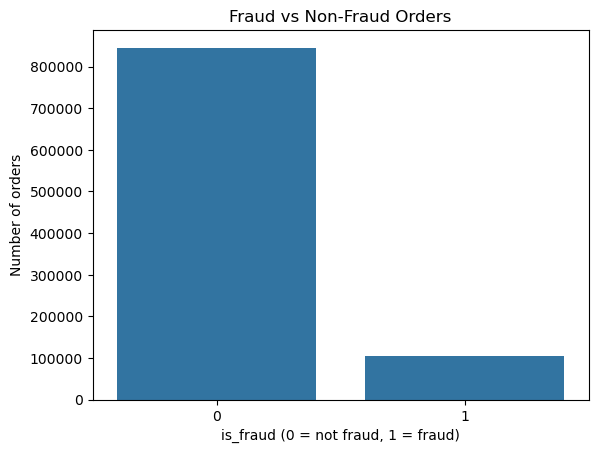

In [18]:
fraud_counts = labels_raw["is_fraud"].value_counts().to_frame("count")
fraud_counts["percent"] = (fraud_counts["count"] / fraud_counts["count"].sum() * 100).round(2)
display(fraud_counts)

sns.countplot(data=labels_raw, x="is_fraud")
plt.title("Fraud vs Non-Fraud Orders")
plt.xlabel("is_fraud (0 = not fraud, 1 = fraud)")
plt.ylabel("Number of orders")
plt.show()

**Imbalanced target**

- **845,814 orders (89.0%)** are not fraud
- **104,504 orders (11.0%)** are fraud
- The target is **imbalanced**, so a model could reach 89% accuracy by predicting "not fraud" for every order
- Accuracy alone is not a suitable metric. **Precision** (how many flagged orders are really fraud) and **recall** (how many fraud orders are caught) should be used, since a model can score high accuracy while catching very few fraud orders
- Imbalance must be handled during model training, for example with class weights
---

**3. Check Repeated `order_id`**

In [19]:
labels_raw[labels_raw["order_id"].duplicated(keep=False)].sort_values("order_id")

,country_code,order_id,customer_id,is_fraud
666815,PK,431b5e1fcd,3d7ad48f9c,0
683871,MY,431b5e1fcd,5d846302c1,0
248428,PH,a4a09bbcbe,5a747496ed,0
258086,MY,a4a09bbcbe,1081c87711,0
241898,MY,ac6b16a277,ee81698ce5,0
742828,PH,ac6b16a277,bb9bd69f57,1


**Repeated order IDs**

- **3 order IDs** appear twice, giving **6 rows**
- Each pair has a **different `country_code`** and a **different `customer_id`**, so they are different orders, not duplicates
- This confirms that an order is identified by **`country_code` and `order_id` together**

---

**4. Check Matching Between Datasets**

In [20]:
# Uppercase country codes for the comparison only, so case differences do not count as mismatches
def keys(df, id_col):
    return set(zip(df["country_code"].str.upper(), df[id_col]))

order_keys = keys(orders_raw, "order_id")
label_order_keys = keys(labels_raw, "order_id")
customer_keys = keys(customers_raw, "customer_id")
label_customer_keys = keys(labels_raw, "customer_id")

print("Labels with no matching order:    ", len(label_order_keys - order_keys))
print("Orders with no matching label:    ", len(order_keys - label_order_keys))
print("Labels with no matching customer: ", len(label_customer_keys - customer_keys))

Labels with no matching order:     444
Orders with no matching label:     15
Labels with no matching customer:  14


**Unmatched records**

- **444 labels** have no matching order
- **15 orders** have no matching label
- **14 distinct customers** keys referenced in the labels dataset have no matching customer record.
- These records cannot be fully joined, so they cannot be used for model training without missing information

---

## **2.4 Numeric Distributions**

**1. Skewness and Outliers**

In [21]:
customer_num_cols = ["num_orders_last_50days", "num_cancelled_orders_last_50days",
                     "num_refund_orders_last_50days", "total_payment_last_50days",
                     "num_associated_customers"]
order_num_cols = ["order_value", "num_items_ordered", "refund_value"]


def distribution_summary(df, cols):
    """Skewness, share of zeros and number of outliers (IQR method) for each column."""
    rows = []
    for col in cols:
        s = df[col].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        upper = q3 + 1.5 * (q3 - q1)
        rows.append({
            "column": col,
            "skewness": round(s.skew(), 2),
            "zero_%": round((s == 0).mean() * 100, 1),
            "upper_limit": round(upper, 2),
            "outliers": int((s > upper).sum()),
            "outlier_%": round((s > upper).mean() * 100, 2),
        })
    return pd.DataFrame(rows).set_index("column")


display(distribution_summary(customers_raw, customer_num_cols))
display(distribution_summary(orders_raw, order_num_cols))

,skewness,zero_%,upper_limit,outliers,outlier_%
column,,,,,
num_orders_last_50days,5.42,6.4,65.00,53579,5.94
num_cancelled_orders_last_50days,55.00,83.1,0.00,151945,16.86
num_refund_orders_last_50days,17.52,85.8,0.00,128372,14.24
total_payment_last_50days,8.68,3.7,908.37,63144,7.01
num_associated_customers,12.48,0.0,6.00,39178,4.35


,skewness,zero_%,upper_limit,outliers,outlier_%
column,,,,,
order_value,6.62,0.0,16.47,56798,5.98
num_items_ordered,41.04,0.0,8.50,69852,7.35
refund_value,8.41,38.7,7.25,71069,7.48


**Skewness and outliers**

- All numeric columns are **right-skewed** (skewness above 1). `num_cancelled_orders_last_50days` (**55.0**) and `num_items_ordered` (**41.0**) are the most skewed
- **4.4% to 7.5%** of values are outliers by the IQR method, except in the cancelled and refund order columns, which are over 83% zeros, so IQR is not meaningful there
- `refund_value` is **0 in 38.7%** of orders

---

**2. Distribution Plots**

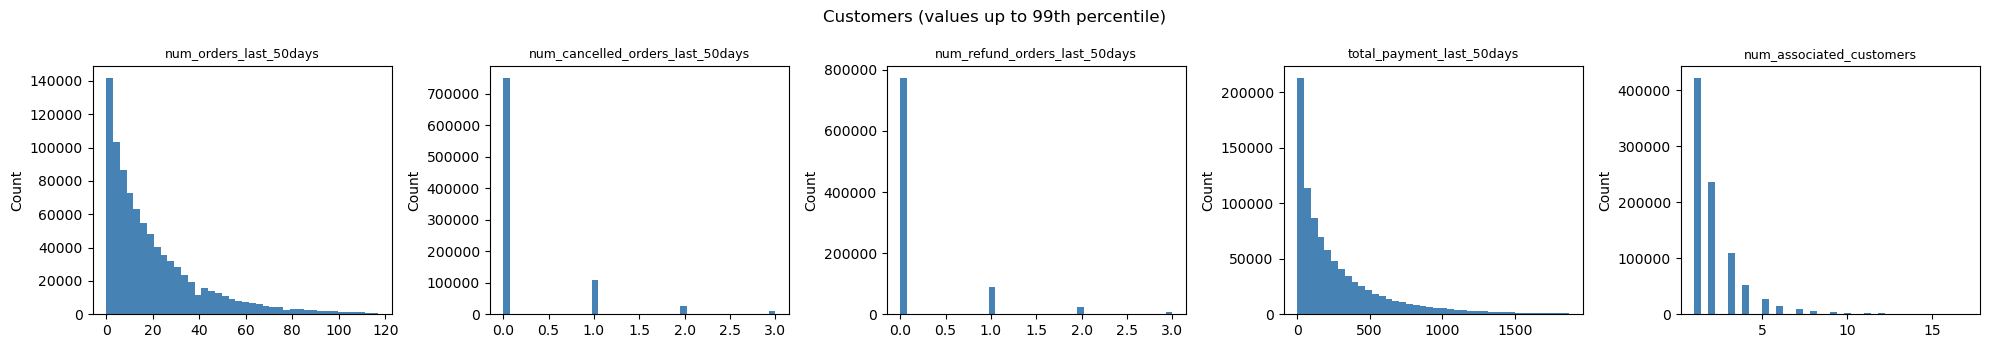

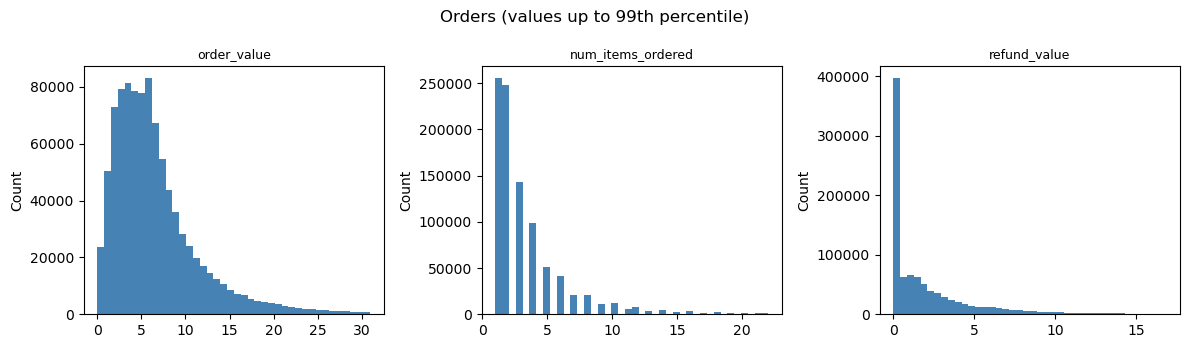

In [22]:
def plot_distributions(df, cols, title):
    """Histogram of each column, cut at the 99th percentile so the shape is visible."""
    fig, axes = plt.subplots(1, len(cols), figsize=(4 * len(cols), 3.5))
    for ax, col in zip(axes, cols):
        s = df[col].dropna()
        s = s[s <= s.quantile(0.99)]
        ax.hist(s, bins=40, color="steelblue")
        ax.set_title(col, fontsize=9)
        ax.set_ylabel("Count")
    fig.suptitle(title + " (values up to 99th percentile)")
    plt.tight_layout()
    plt.show()


plot_distributions(customers_raw, customer_num_cols, "Customers")
plot_distributions(orders_raw, order_num_cols, "Orders")

**Distribution shape**

- All columns have a **long right tail**: most values are small and a few are very large
- The plots stop at the 99th percentile only to make the shape visible. No data is removed
- Skewness is reduced with a **log transform** in feature engineering

---

**3. Check `num_associated_customers` Upper Values**

In [23]:
customers_raw["num_associated_customers"].value_counts().sort_index().tail(8).to_frame("count")

,count
num_associated_customers,
94,21
95,16
96,21
97,18
98,15
99,8
100,2251
101,325


**Possible cap at 100**

- Only **8 customers** have 99, but **2,251** have 100 and **325** have 101, which suggests the value is **capped at 100**
- These customers are kept, as a high value is likely a fraud signal

---

# **3. Fraud Analysis**

## **3.1 Join Datasets for Analysis**

The three datasets are joined so the fraud label can be compared with customer and order details. Country codes are converted to uppercase for the join only, so that case differences do not prevent matching. The full cleaning is done in Section 4.

In [24]:
def upper_country(df):
    return df.assign(country_code=df["country_code"].str.upper())


analysis_df = (
    upper_country(labels_raw)
    .merge(upper_country(orders_raw), on=["country_code", "order_id"], how="inner")
    .merge(upper_country(customers_raw), on=["country_code", "customer_id"], how="left")
)

print("Joined rows:", len(analysis_df))
print("Overall fraud rate: {:.2f}%".format(analysis_df["is_fraud"].mean() * 100))

Joined rows: 949874
Overall fraud rate: 10.99%


**Joined data**

- **949,874 orders** have both a label and order details
- The overall fraud rate is **10.99%**, used as the baseline for comparing groups below

---

## **3.2 Fraud Rate by Category**

In [25]:
def fraud_rate_by(df, col):
    """Number of orders and fraud rate (%) for each value of a column, missing shown as 'missing'."""
    table = (df.groupby(df[col].fillna("missing"))["is_fraud"]
               .agg(orders="size", fraud_rate="mean"))
    table["fraud_rate"] = (table["fraud_rate"] * 100).round(2)
    return table.sort_values("fraud_rate", ascending=False)


for col in ["country_code", "collect_type", "payment_method"]:
    display(fraud_rate_by(analysis_df, col))

,orders,fraud_rate
country_code,,
BD,59558,29.27
PK,184820,24.52
PH,281207,8.47
TH,63726,5.97
MY,360563,3.90


,orders,fraud_rate
collect_type,,
pickup,12074,28.82
Delivery,937715,10.76
delivery,85,9.41


,orders,fraud_rate
payment_method,,
jazzcash wallet,2509,48.90
no payment,670,32.69
antfinancial bkash,17888,25.98
generic creditcard,72318,19.43
payment on Delivery,312444,16.08
balance,25936,16.01
invoice,1963,15.49
on Delivery,160,13.75
payment on delivery,20,10.00


**Fraud by category**

- **Country:** highest in **BD (29.27%)** and **PK (24.52%)**, lowest in **MY (3.90%)**
- **Collect type:** **pickup** (**28.82%**) is more than double delivery (**10.76%**)
- **Payment method:** ranges from **48.90%** (`jazzcash wallet`) to **4% or less** (`cybersource`, `online banking`)
- `no payment` (**32.69%**) is three times the baseline, so it is kept as its own category
- Missing payment method is only **4.93%**, so missing values are kept as `unknown`

---

## **3.3 Fraud Rate by Refund and Missing Date**

In [26]:
analysis_df["refund_group"] = np.where(analysis_df["refund_value"] > 0, "refund > 0", "refund = 0")
analysis_df["first_order_missing"] = analysis_df["first_order_datetime"].isna()

display(fraud_rate_by(analysis_df, "refund_group"))
display(fraud_rate_by(analysis_df, "first_order_missing"))

,orders,fraud_rate
refund_group,,
refund = 0,367934,28.38
refund > 0,581940,0.00


,orders,fraud_rate
first_order_missing,,
True,773,23.93
False,949101,10.98


**Refund value**

- Fraud rate is **28.38%** when the refund is 0, and **0.00%** when there is any refund
- **Every fraud order has a refund of 0**, but most zero-refund orders (**71.62%**) are not fraud, so a zero refund alone does not identify fraud
- This pattern suggests the refund is recorded **after** the fraud decision, for example because refunds on fraud orders are blocked
- `refund_value` is not known when an order is placed, so using it as a feature would cause **data leakage**: the model would look accurate in testing but fail on new orders


**Missing first order date**

- Orders from customers with no `first_order_datetime` have a fraud rate of **23.93%**, more than double the baseline
- The missing date is itself a fraud signal, so these customers are kept and a missing-value indicator is considered in feature engineering

---

## **3.4 Fraud Rate in Extreme Values**

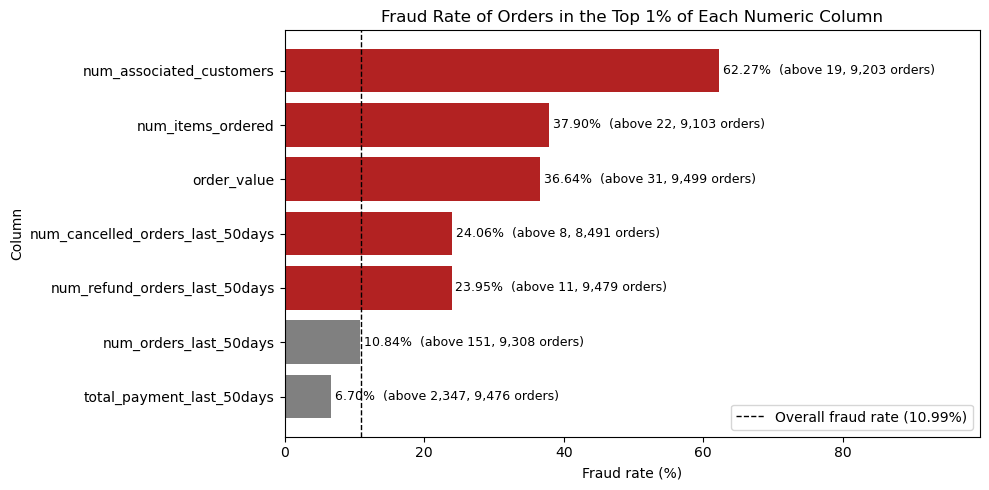

In [27]:
extreme_cols = ["order_value", "num_items_ordered", "num_associated_customers",
                "num_refund_orders_last_50days", "num_cancelled_orders_last_50days",
                "num_orders_last_50days", "total_payment_last_50days"]

rows = []
for col in extreme_cols:
    p99 = analysis_df[col].quantile(0.99)
    top = analysis_df[analysis_df[col] > p99]
    rows.append({"column": col, "p99": p99, "orders_above": len(top),
                 "fraud_rate": top["is_fraud"].mean() * 100})

extreme_df = pd.DataFrame(rows).sort_values("fraud_rate")
baseline = analysis_df["is_fraud"].mean() * 100

fig, ax = plt.subplots(figsize=(10, 5))
colors = ["firebrick" if r > baseline else "grey" for r in extreme_df["fraud_rate"]]
bars = ax.barh(extreme_df["column"], extreme_df["fraud_rate"], color=colors)
ax.axvline(baseline, color="black", linestyle="--", linewidth=1,
           label=f"Overall fraud rate ({baseline:.2f}%)")

for bar, (_, row) in zip(bars, extreme_df.iterrows()):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
            f"{row['fraud_rate']:.2f}%  (above {row['p99']:,.0f}, {row['orders_above']:,} orders)",
            va="center", fontsize=9)

ax.set_title("Fraud Rate of Orders in the Top 1% of Each Numeric Column")
ax.set_xlabel("Fraud rate (%)")
ax.set_ylabel("Column")
ax.set_xlim(0, extreme_df["fraud_rate"].max() * 1.6)
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Extreme values and fraud**

- The top 1% of `num_associated_customers` has a fraud rate of **62.27%**, and of `num_items_ordered` (**37.90%**) and `order_value` (**36.64%**), over three times the baseline
- High refund and cancelled order counts are also linked to fraud (about **24%**)
- `num_orders_last_50days` (**10.84%**) and `total_payment_last_50days` (**6.70%**) show no increase
- Removing extreme values would remove many fraud cases, so they are **kept**

---

# **4. Data Inspection Summary**

**1. Customers Dataset**

- Lowercase country codes (`pk`, `my`) in **390 rows**
- `mobile_verified` contains `yes` in **165 rows** instead of True or False
- **712 missing** `first_order_datetime` values
- All numeric columns are **heavily right-skewed**
- `num_associated_customers` appears to be **capped at 100**
- No duplicate customers and no negative values

---

**2. Orders Dataset**

- Inconsistent case in `collect_type` and `payment_method`
- **21,501 missing** payment methods
- **Three different date formats** in `order_date`
- **1 missing** `num_items_ordered`
- **23 orders** with an order value of 0
- **199,687 orders** with a refund value greater than the order value
- 3 repeated order IDs, which are different orders in different countries

---

**3. Labels Dataset**

- Lowercase country codes (`ph`, `my`) in **301 rows**
- Imbalanced target: **11.0% fraud** and **89.0% not fraud**
- **444 labels** with no matching order, **15 orders** with no label, and **14 customer keys** in the labels file with no matching customer record

---

**4. Fraud Analysis**

- Fraud varies strongly by country, collect type and payment method
- **No fraud order has a refund**, so `refund_value` reveals the fraud outcome
- Extreme values are linked to higher fraud, especially `num_associated_customers` (**62.27%** in the top 1%)

## **4.1 Assumptions and Justifications**

Each issue is listed with the assumption made, the evidence for it, and the action taken in the cleaning stage.

---

**1. Lowercase country codes**
- **Assumption:** `pk`, `my` and `ph` are the same countries as `PK`, `MY` and `PH`
- **Justification:** They are valid country codes written in a different letter case
- **Action:** Convert all country codes to uppercase

**2. `yes` in `mobile_verified`**
- **Assumption:** `yes` means the mobile number is verified
- **Justification:** `yes` has the same meaning as `True`, and the column should only hold True or False
- **Action:** Convert `yes` to `True`

**3. Inconsistent `collect_type`**
- **Assumption:** `Delivery` and `delivery` are the same value
- **Justification:** The values only differ in letter case
- **Action:** Standardise to `Delivery` and `Pickup`

**4. Inconsistent `payment_method`**
- **Assumption:** `payment on Delivery`, `payment on delivery` and `on Delivery` are the same method, and `Online Banking` and `online banking` are the same method
- **Justification:** The values differ only in letter case or a shortened name, so keeping them separate would split one category into several
- **Action:** Merge each group into one value

**5. `no payment` value**

- **Assumption:** `no payment` may represent unpaid orders, pending payments or failed transactions rather than an actual payment method. Its exact meaning is unknown.
- **Justification:** Of the 670 orders recorded as `no payment`, **97.76% have a positive order value**, with a median of **$5.71**. This suggests that the category is unlikely to primarily represent free orders. Its fraud rate of **32.69%** also indicates an association with fraud, but does not establish its business meaning.
- **Action:** Keep `no payment` separate from missing values (`unknown`) and document its uncertain meaning. Confirm that this information is available at prediction time before using it as a model feature.

**6. Missing `payment_method` (21,501 orders)**
- **Assumption:** The payment method was not recorded, but the orders are valid
- **Justification:** These orders have a fraud rate of only **4.93%**, so dropping them would remove mostly genuine orders and make the data look more fraudulent than it is
- **Action:** Fill missing values with `unknown`

**7. Three date formats in `order_date`**
- **Assumption:** All formats are in year, month, day order
- **Justification:** Every format starts with a four-digit year, and the month names confirm the month position
- **Action:** Convert all dates to one date format

**8. Missing `first_order_datetime` (712 customers)**
- **Assumption:** The date was not recorded, but the rest of the customer information is valid
- **Justification:** Their orders have a fraud rate of **23.93%**, more than double the baseline, so the missing date is itself a fraud signal
- **Action:** Keep these customers, leave the date empty, and add a missing-value indicator in feature engineering

**9. Missing `num_items_ordered` (1 order)**
- **Assumption:** The number of items was not recorded, but the order is valid
- **Justification:** Filling with the median keeps the order, and the pipeline will not drop rows if new data has more missing values
- **Action:** Fill the missing value with the **historical median (2)**, so every new batch uses the same value

**10. `order_value` of 0 (23 orders)**
- **Assumption:** These are valid orders, such as fully discounted or free orders
- **Justification:** The other columns are filled in, and 23 orders is too few to affect the model
- **Action:** Keep these orders unchanged

**11. Repeated `order_id`**
- **Assumption:** Each repeated ID belongs to a different order
- **Justification:** Each pair has a different country, customer, date and order value
- **Action:** Identify orders by `country_code` and `order_id` together

**12. `num_associated_customers` appears capped at 100**
- **Assumption:** Values of 100 and above represent customers with **100 or more** associated customers, as the true count appears to be cut off
- **Justification:** The number of customers falls steadily up to 99 (only **8** customers), then jumps to **2,251** at 100 and **325** at 101. Real counts do not jump like this, which suggests a recording limit. The reason for the value 101 is unknown
- **Action:** Keep the values unchanged, as a high value is still a strong fraud signal, and add an `associated_capped` flag in feature engineering

**13. Extreme values**
- **Assumption:** Values such as 2,162 orders in 50 days or 1,600 items in one order are real
- **Justification:** Orders in the top 1% of `num_items_ordered` and `order_value` have fraud rates above **36%**, so removing them would remove many fraud cases
- **Action:** Keep them, and reduce skewness during feature engineering

**14. Unmatched records**
- **Assumption:** Records that cannot be matched are genuinely missing from the other file, not caused by a joining error. Country codes are converted to uppercase first, so case differences do not cause mismatches
- **Justification:** A training row needs a fraud label, order details and customer details together. The 444 labels without an order and 2 orders without a customer have no complete row, and the 15 orders without a label have nothing to train on
- **Action:** Exclude them from model training. The merge removes **446 rows** (950,318 labels to 949,872 merged orders)

**15. `refund_value` greater than `order_value` (199,687 orders)**
- **Assumption:** These values are kept as recorded
- **Justification:** This affects about **21%** of orders, and the correct refund amount cannot be determined from the data, so changing or removing these orders would lose data or introduce bias. `refund_value` is also not used as a model feature (Assumption 16), so these values do not affect the model
- **Action:** Keep these orders unchanged

**16. `refund_value` as a model input**
- **Assumption:** `refund_value` is recorded after the fraud decision
- **Justification:** Every fraud order has a refund of 0, and no order with a refund is fraud (**0.00%**), so the column reflects the fraud decision. It is not known when an order is placed, so a model using it would fail on new orders
- **Action:** Keep `refund_value` in the database, but exclude it from model features

**17. Order date before the first order date (105 orders)**

- **Assumption:** One of the two dates may have been recorded incorrectly, since an order cannot occur before the customer's actual first order.
- **Justification:** There are 105 affected orders, with negative account ages of up to 119 days. Removing these orders would result in unnecessary data loss. However, replacing negative ages with zero alone would make them indistinguishable from genuine new accounts.
- **Action:** Keep these orders and create an `account_age_invalid` indicator (1 = invalid negative age, 0 = otherwise). Replace negative account ages with zero for numerical processing, while retaining the indicator to distinguish invalid records from genuine new accounts. The existing `first_order_missing` indicator continues to identify missing dates.

**18. Values that cannot be fixed in new data**
- **Assumption:** Some rows in new data may have problems that cannot be fixed safely, such as an unknown date format, a non-numeric value or a negative count
- **Justification:** Guessing these values could put wrong data into the database and models, while dropping them silently would hide the problem
- **Action:** Move these rows to a rejected table with a reason, so every input row is either cleaned or recorded

**19. Customer snapshot columns**
- **Assumption:** The customer file appears to be a single snapshot taken around **11 May 2023**, not recorded at the time of each order. This affects the 50-day columns, `mobile_verified` and `num_associated_customers`
- **Justification:** The latest first order date (10 May 2023) is one day before the latest order date (11 May 2023), and **73.46%** of orders were placed before the assumed 50-day window (Section 6.2). These features may contain information that was not available when the order was placed, which is potential data leakage. The snapshot timing cannot be confirmed from the data
- **Action:** List the 10 affected features in `SNAPSHOT_FEATURES`. Compare models with and without them, but **exclude them from the final model**, as required by the rule that features must only use information available at assessment time. The customer information is kept in the data for analysis and reporting

# **5. Data Cleaning and Validation**

Each dataset is cleaned by one function, so the same steps can be applied to new data in the ETL pipeline. The functions follow the assumptions in Section 4.1.

## **5.1 Helper Functions**

In [28]:
def clean_text(s):
    """Strip spaces and turn empty strings into missing values."""
    s = s.astype("object").where(s.notna(), None)
    s = s.map(lambda x: x.strip() if isinstance(x, str) else x)
    return s.replace({"": np.nan, "nan": np.nan, "NaN": np.nan, "None": np.nan})


def clean_country(s):
    """Assumption 1: country codes in uppercase."""
    return clean_text(s).str.upper()


def to_number(s):
    """Convert to numbers; text and infinite values become missing."""
    result = pd.to_numeric(s, errors="coerce")
    return result.replace([np.inf, -np.inf], np.nan)


BOOL_MAP = {"true": True, "yes": True, "y": True, "1": True,
            "false": False, "no": False, "n": False, "0": False}


def clean_bool(s):
    """Assumption 2: map text such as 'yes' or 'TRUE' to True or False."""
    return clean_text(s).astype(str).str.lower().map(BOOL_MAP)


DATE_FORMATS = ["%Y/%m/%d", "%Y-%m-%d", "%Y/%b/%d"]


def parse_dates(s, formats=DATE_FORMATS):
    """Assumption 7: try each known date format; values matching none stay missing."""
    s = clean_text(s)
    result = pd.Series(pd.NaT, index=s.index)
    for fmt in formats:
        missing = result.isna() & s.notna()
        result[missing] = pd.to_datetime(s[missing], format=fmt, errors="coerce")
    return result


def reject(df, mask, reason, rejected):
    """Assumption 18: move rows that cannot be fixed into the rejected list with a reason."""
    if mask.any():
        rejected.append(df[mask].assign(reason=reason))
    return df[~mask]


def combine_rejected(rejected, columns):
    """Join all rejected rows into one table (empty table if none)."""
    if rejected:
        return pd.concat(rejected, ignore_index=True)
    return pd.DataFrame(columns=list(columns) + ["reason"])

**Helper functions**

- Each helper fixes one type of problem and is shared by all three datasets, so each fix is written once
- Unexpected values in new data (e.g. extra spaces, `no`, `1`) are still handled
- Rows that cannot be fixed, such as an unknown date format, are moved to a **rejected table with a reason**, so no row disappears without a record

---

## **5.2 Clean Customers**

In [29]:
CUSTOMER_COUNT_COLS = ["num_orders_last_50days", "num_cancelled_orders_last_50days",
                       "num_refund_orders_last_50days", "num_associated_customers"]
CUSTOMER_NUM_COLS = CUSTOMER_COUNT_COLS + ["total_payment_last_50days"]


def clean_customers(df):
    """Return (cleaned customers, rejected customers with a reason)."""
    df = df.copy()
    rejected = []
    df["country_code"] = clean_country(df["country_code"])
    df["customer_id"] = clean_text(df["customer_id"])
    df = reject(df, df["country_code"].isna() | df["customer_id"].isna(), "missing country_code or customer_id", rejected)
    df["mobile_verified"] = clean_bool(df["mobile_verified"])
    df = reject(df, df["mobile_verified"].isna(), "unrecognised mobile_verified", rejected)
    for col in CUSTOMER_NUM_COLS:
        df[col] = to_number(df[col])
    df = reject(df, df[CUSTOMER_NUM_COLS].isna().any(axis=1), "missing or non-numeric value", rejected)
    df = reject(df, (df[CUSTOMER_NUM_COLS] < 0).any(axis=1), "negative value", rejected)
    # Counts must be whole numbers (total payment can have decimals)
    df = reject(df, (df[CUSTOMER_COUNT_COLS] % 1 != 0).any(axis=1), "count is not a whole number", rejected)
    # Assumption 8: a missing first order date is allowed, but a date that cannot be read is rejected
    raw_date = clean_text(df["first_order_datetime"])
    parsed = pd.to_datetime(raw_date, format="ISO8601", errors="coerce")
    df = reject(df, raw_date.notna() & parsed.isna(), "unparseable first_order_datetime", rejected)
    df["first_order_datetime"] = parsed[df.index]
    df = reject(df, df.duplicated(["country_code", "customer_id"], keep="last"), "duplicate customer (kept last in file)", rejected)
    return df.reset_index(drop=True), combine_rejected(rejected, df.columns)

## **5.3 Clean Orders**

In [30]:
COLLECT_MAP = {"delivery": "Delivery", "pickup": "Pickup"}
PAYMENT_MAP = {"on delivery": "payment on delivery"}
ITEMS_FILL_VALUE = 2  # median of num_items_ordered in the historical data
ORDER_NUM_COLS = ["order_value", "num_items_ordered", "refund_value"]


def clean_orders(df, items_fill_value=ITEMS_FILL_VALUE):
    """Return (cleaned orders, rejected orders with a reason)."""
    df = df.copy()
    rejected = []
    df["country_code"] = clean_country(df["country_code"])
    df["order_id"] = clean_text(df["order_id"])
    df = reject(df, df["country_code"].isna() | df["order_id"].isna(), "missing country_code or order_id", rejected)
    # Assumption 3: standardise collect type
    df["collect_type"] = clean_text(df["collect_type"]).str.lower().map(COLLECT_MAP)
    df = reject(df, df["collect_type"].isna(), "unrecognised collect_type", rejected)
    # Assumptions 4 and 6: merge payment variants, fill missing with "unknown"
    payment = clean_text(df["payment_method"]).str.lower().replace(PAYMENT_MAP)
    df["payment_method"] = payment.fillna("unknown")
    raw_items = clean_text(df["num_items_ordered"])
    for col in ORDER_NUM_COLS:
        df[col] = to_number(df[col])
    # Text such as "abc" is rejected; only a truly empty item count is filled
    df = reject(df, raw_items.notna() & df["num_items_ordered"].isna(), "non-numeric item count", rejected)
    # Assumption 9: fill missing item count with the historical median
    df["num_items_ordered"] = df["num_items_ordered"].fillna(items_fill_value)
    df = reject(df, df[ORDER_NUM_COLS].isna().any(axis=1), "missing or non-numeric value", rejected)
    df = reject(df, (df[ORDER_NUM_COLS] < 0).any(axis=1), "negative value", rejected)
    # An item count must be a whole number of at least 1
    df = reject(df, (df["num_items_ordered"] % 1 != 0) | (df["num_items_ordered"] < 1),
                "item count not a whole number of at least 1", rejected)
    df["num_items_ordered"] = df["num_items_ordered"].astype(int)
    df["order_date"] = parse_dates(df["order_date"])
    df = reject(df, df["order_date"].isna(), "missing or unknown order_date format", rejected)
    # Assumption 11: an order is identified by country_code and order_id together
    df = reject(df, df.duplicated(["country_code", "order_id"], keep="last"),
                "duplicate order (kept last in file)", rejected)
    return df.reset_index(drop=True), combine_rejected(rejected, df.columns)

## **5.4 Clean Labels**

In [31]:
def clean_labels(df):
    """Return (cleaned labels, rejected labels with a reason)."""
    df = df.copy()
    rejected = []
    df["country_code"] = clean_country(df["country_code"])
    df["order_id"] = clean_text(df["order_id"])
    df["customer_id"] = clean_text(df["customer_id"])
    df = reject(df, df[["country_code", "order_id", "customer_id"]].isna().any(axis=1), "missing ID", rejected)
    df["is_fraud"] = to_number(df["is_fraud"])
    df = reject(df, ~df["is_fraud"].isin([0, 1]), "is_fraud not 0 or 1", rejected)
    df["is_fraud"] = df["is_fraud"].astype(int)
    df = reject(df, df.duplicated(["country_code", "order_id"], keep="last"), "duplicate order (kept last in file)", rejected)
    return df.reset_index(drop=True), combine_rejected(rejected, df.columns)

**Cleaning functions**

- Each function returns **two tables**: the cleaned rows and the rejected rows with a reason, so cleaned + rejected always equals the input
- Each function works on a **copy**, so the raw data is never changed
- Missing item counts are filled with the **historical median (2)**, so every new batch uses the same value
- Duplicates in new data keep the **last row in the file**, and earlier rows are rejected, since the data has no timestamp to tell which is newest
---

## **5.5 Apply Cleaning**

In [32]:
customers_clean, customers_rejected = clean_customers(customers_raw)
orders_clean, orders_rejected = clean_orders(orders_raw)
labels_clean, labels_rejected = clean_labels(labels_raw)

pd.DataFrame({
    "Dataset": ["customers", "orders", "labels"],
    "Rows in": [len(customers_raw), len(orders_raw), len(labels_raw)],
    "Cleaned": [len(customers_clean), len(orders_clean), len(labels_clean)],
    "Rejected": [len(customers_rejected), len(orders_rejected), len(labels_rejected)],
})

,Dataset,Rows in,Cleaned,Rejected
0,customers,901312,901312,0
1,orders,949889,949889,0
2,labels,950318,950318,0


In [33]:
display(customers_clean["country_code"].value_counts().to_frame("count"))
display(customers_clean["mobile_verified"].value_counts().to_frame("count"))
display(orders_clean["collect_type"].value_counts().to_frame("count"))
display(orders_clean["payment_method"].value_counts().to_frame("count"))
print("order_date range:", orders_clean["order_date"].min(), "to", orders_clean["order_date"].max())

,count
country_code,
MY,339299
PH,289358
PK,152102
TH,72509
BD,48044


,count
mobile_verified,
True,900846
False,466


,count
collect_type,
Delivery,937815
Pickup,12074


,count
payment_method,
payment on delivery,312627
cybersource,135418
online banking,124983
credit card,114242
antfinancial gcash,102657
generic creditcard,72319
balance,25936
unknown,21501
antfinancial bkash,17889


order_date range: 2022-11-12 00:00:00 to 2023-05-11 00:00:00


**Cleaning results**

- **No rows were rejected** from any dataset, since every problem in the base data could be fixed
- Country codes, `mobile_verified` and `collect_type` now contain only valid values
- Payment methods went from **21** values to **18**, with missing values shown as `unknown`
- All order dates were converted, from **2022-11-12** to **2023-05-11**

---

## **5.6 Validation**

In [34]:
def validate(customers, orders, labels):
    """Count the rows that fail each check. A check passes when 0 rows fail."""
    checks = {
        "customers: country codes uppercase": (customers["country_code"] != customers["country_code"].str.upper()).sum(),
        "customers: mobile_verified True/False only": (~customers["mobile_verified"].isin([True, False])).sum(),
        "customers: no duplicate customers": customers.duplicated(["country_code", "customer_id"]).sum(),
        "customers: no missing numbers": customers[CUSTOMER_NUM_COLS].isna().sum().sum(),
        "customers: no negative numbers": (customers[CUSTOMER_NUM_COLS] < 0).sum().sum(),
        "customers: counts are whole numbers": (customers[CUSTOMER_COUNT_COLS] % 1 != 0).sum().sum(),
        "orders: country codes uppercase": (orders["country_code"] != orders["country_code"].str.upper()).sum(),
        "orders: collect_type Delivery/Pickup only": (~orders["collect_type"].isin(["Delivery", "Pickup"])).sum(),
        "orders: no missing payment_method": orders["payment_method"].isna().sum(),
        "orders: item count whole number of at least 1": ((orders["num_items_ordered"] < 1) | (orders["num_items_ordered"] % 1 != 0)).sum(),
        "orders: all order_date parsed": orders["order_date"].isna().sum(),
        "orders: no missing numbers": orders[ORDER_NUM_COLS].isna().sum().sum(),
        "orders: no negative numbers": (orders[ORDER_NUM_COLS] < 0).sum().sum(),
        "orders: no duplicate orders": orders.duplicated(["country_code", "order_id"]).sum(),
        "labels: country codes uppercase": (labels["country_code"] != labels["country_code"].str.upper()).sum(),
        "labels: is_fraud 0/1 only": (~labels["is_fraud"].isin([0, 1])).sum(),
        "labels: no duplicate orders": labels.duplicated(["country_code", "order_id"]).sum(),
    }
    report = pd.DataFrame({"failed_rows": pd.Series(checks)})
    report["passed"] = report["failed_rows"] == 0
    return report


validate(customers_clean, orders_clean, labels_clean)

,failed_rows,passed
customers: country codes uppercase,0,True
customers: mobile_verified True/False only,0,True
customers: no duplicate customers,0,True
customers: no missing numbers,0,True
customers: no negative numbers,0,True
customers: counts are whole numbers,0,True
orders: country codes uppercase,0,True
orders: collect_type Delivery/Pickup only,0,True
orders: no missing payment_method,0,True
orders: item count whole number of at least 1,0,True


**Validation results**

- All **17 checks passed**
- Validation is the **final safety check** before data is loaded into the database. Rows that cannot be fixed are already rejected during cleaning, so a failed check means a cleaning rule is missing

---

## **5.7 Test on Messy Sample Data**

A small sample with problems not found in the base data is used to confirm that the functions work on new data.

In [35]:
test_customers = pd.DataFrame({
    "country_code": [" my", "PK", "ph", None, "TH", "TH", "BD", "BD"],
    "customer_id": ["a1", "b2 ", "c3", "d4", "e5", "e5", "f6", "g7"],
    "mobile_verified": ["TRUE", "no", "maybe", "1", "yes", "False", "true", "false"],
    "num_orders_last_50days": ["3", "x", "5", "1", "4", "2", "2.7", "6"],
    "num_cancelled_orders_last_50days": [0, 0, 0, 0, 0, 0, 0, 0],
    "num_refund_orders_last_50days": [0, 1, 0, 0, -1, 0, 0, 0],
    "total_payment_last_50days": ["10.5", "2", "", "3", "4", "5", "8", "inf"],
    "num_associated_customers": [1, 2, 3, 4, 5, 6, 1, 1],
    "first_order_datetime": ["2021-01-01 10:00:00", "", None, "2020-02-02", "2020-02-02", "not a date", "2021-01-01", "2021-01-01"],
})
test_orders = pd.DataFrame({
    "country_code": ["my", "PK", "PK", "BD", "TH", "MY", "MY", "MY"],
    "order_id": ["o1", "o2", "o2", "o3", "o4", "o5", "o6", "o7"],
    "collect_type": [" delivery", "PICKUP", "Pickup", "Delivery", "drone", "Delivery", "Delivery", "Delivery"],
    "payment_method": ["On Delivery", None, "  ", "Credit Card", "paypal", "grabpay", "paypal", "paypal"],
    "order_value": ["5", "6", "6", "x", "3", "4", "5", "5"],
    "num_items_ordered": [None, "3", "3", "2.0", "1", "2", "abc", "0"],
    "refund_value": [0, 1, 1, 0, 0, 0, 0, 0],
    "order_date": ["2023/Jun/01", "2023-07-02", "2023/07/03", "2023/07/04", "2023/07/05", "05/08/2023", "2023/07/06", "2023/07/07"],
})
test_labels = pd.DataFrame({
    "country_code": ["my", "pk", "bd"],
    "order_id": ["o1", "o2", "o3"],
    "customer_id": ["a1", "b2", None],
    "is_fraud": ["1", "2", "0"],
})

test_c, test_c_rej = clean_customers(test_customers)
test_o, test_o_rej = clean_orders(test_orders)
test_l, test_l_rej = clean_labels(test_labels)

display(pd.concat([test_c_rej[["customer_id", "reason"]].assign(table="customers"),
                   test_o_rej[["order_id", "reason"]].assign(table="orders"),
                   test_l_rej[["order_id", "reason"]].assign(table="labels")], ignore_index=True))

print("Customers in/out:", len(test_customers), "=", len(test_c), "+", len(test_c_rej))
print("Orders in/out:   ", len(test_orders), "=", len(test_o), "+", len(test_o_rej))
print("Labels in/out:   ", len(test_labels), "=", len(test_l), "+", len(test_l_rej))
print("All validation checks passed:", validate(test_c, test_o, test_l)["passed"].all())

,customer_id,reason,table,order_id
0,d4,missing country_code or customer_id,customers,NaN
1,c3,unrecognised mobile_verified,customers,NaN
2,b2,missing or non-numeric value,customers,NaN
3,g7,missing or non-numeric value,customers,NaN
4,e5,negative value,customers,NaN
5,f6,count is not a whole number,customers,NaN
6,e5,unparseable first_order_datetime,customers,NaN
7,NaN,unrecognised collect_type,orders,o4
8,NaN,non-numeric item count,orders,o6
9,NaN,missing or non-numeric value,orders,o3


Customers in/out: 8 = 1 + 7
Orders in/out:    8 = 2 + 6
Labels in/out:    3 = 1 + 2
All validation checks passed: True


**Sample test results**

- Fixable problems such as spaces, mixed case, `TRUE`, `no`, `1` and missing item counts were cleaned
- Rows that could not be fixed were **rejected with a reason**, such as `maybe` in `mobile_verified`, a negative value, a fractional count (`2.7` orders), an infinite value, a non-numeric item count (`abc`), zero items, an unknown collect type (`drone`) and an unknown date format (`05/08/2023`)
- Every input row is either cleaned or rejected, so **no row disappears without a record**
- All validation checks passed on the cleaned rows

---

# **6. Merge and Feature Engineering**

## **6.1 Merge Datasets**

The cleaned datasets are joined using `country_code` with `order_id` and `customer_id`. Only orders with a label, order details and customer details are kept (Assumption 14).

In [36]:
def merge_datasets(customers, orders, labels):
    """Assumption 14: keep only orders that have a label, order details and customer details."""
    matched = labels.merge(orders, on=["country_code", "order_id"], how="inner", validate="one_to_one")
    merged = matched.merge(customers, on=["country_code", "customer_id"], how="inner", validate="many_to_one")
    print("Labels without a matching order:   ", len(labels) - len(matched))
    print("Orders without a matching customer:", len(matched) - len(merged))
    return merged


merged = merge_datasets(customers_clean, orders_clean, labels_clean)

print("Labels:        ", len(labels_clean))
print("Merged rows:   ", len(merged))
print("Fraud rate:     {:.2f}%".format(merged["is_fraud"].mean() * 100))

print("Duplicate orders after merge:", merged.duplicated(["country_code", "order_id"]).sum())

Labels without a matching order:    444
Orders without a matching customer: 2
Labels:         950318
Merged rows:    949872
Fraud rate:     10.99%
Duplicate orders after merge: 0


**Merge results**

- **949,872 orders** remain after the merge, from **950,318 labels**
- The **446 removed rows** are the 444 labels with no matching order and 2 orders with no matching customer
- The fraud rate stays at **10.99%**, so the merge did not change the class balance
- There are **no duplicate orders** after the merge, so each order appears once with one label

---

## **6.2 Check Account Age**

In [37]:
account_age = (merged["order_date"] - merged["first_order_datetime"].dt.normalize()).dt.days

print("Orders before the customer's first order:", (account_age < 0).sum())
print("Earliest:", account_age.min(), "days")
print("Missing first order date:", account_age.isna().sum())

Orders before the customer's first order: 105
Earliest: -119.0 days
Missing first order date: 771


**Negative account age**

- **105 orders** are dated **before** the customer's first order, by up to **119 days**, which is not possible
- This is likely a recording error in either date
- These orders are kept rather than removed, since the other order information may still be valid
- Negative account ages are set to **0** for numerical processing, but an `account_age_invalid` flag is created to distinguish them from genuine new accounts (Assumption 17)
- Missing first-order dates are handled separately using the existing `first_order_missing` indicator

---

**Check Customer Snapshot Timing**

In [38]:
latest_order = merged["order_date"].max()
latest_first_order = merged["first_order_datetime"].max()
window_start = latest_order - pd.Timedelta(days=50)
before_window = (merged["order_date"] < window_start).mean() * 100

print("Latest order date:          ", latest_order.date())
print("Latest first order date:    ", latest_first_order.date())
print("Assumed 50-day window start:", window_start.date())
print("Orders before the window:    {:.2f}%".format(before_window))

Latest order date:           2023-05-11
Latest first order date:     2023-05-10
Assumed 50-day window start: 2023-03-22
Orders before the window:    73.46%



**Customer snapshot timing**

- The latest first-order date (**10 May 2023**) is one day before the latest order date (**11 May 2023**). This suggests that the customer dataset may represent a single snapshot near the end of the historical period, but the actual snapshot date cannot be confirmed.
- If the snapshot was taken around 11 May 2023, its "last 50 days" would cover approximately **22 March to 11 May 2023**. **73.46%** of historical orders were placed before this assumed window.
- The customer statistics may therefore contain information recorded after individual orders were placed, creating potential temporal data leakage.
- Since the availability of these customer features at prediction time cannot be established, the **10 features in `SNAPSHOT_FEATURES` will be excluded from the final model** (Assumption 19).
- Models with and without these features will be compared during PBI 2 for exploratory analysis. However, a performance difference alone does not prove data leakage.

---

## **6.3 Feature Engineering**


In [39]:
COUNTRIES = ["BD", "MY", "PH", "PK", "TH"]
COLLECT_TYPES = ["Delivery", "Pickup"]
PAYMENT_METHODS = ["payment on delivery", "cybersource", "online banking", "credit card",
                   "antfinancial gcash", "generic creditcard", "balance", "unknown",
                   "antfinancial bkash", "antfinancial truemoney", "boost wallet",
                   "jazzcash wallet", "invoice", "adyen hpp molpay", "no payment",
                   "cybersource applepay", "paypal"]
SKEWED_COLS = ["order_value", "num_items_ordered", "num_orders_last_50days",
               "num_cancelled_orders_last_50days", "num_refund_orders_last_50days",
               "total_payment_last_50days", "num_associated_customers"]

# Features from the customer snapshot, whose timing is unconfirmed (Assumption 19)
SNAPSHOT_FEATURES = ["cancel_rate", "refund_rate", "avg_payment_per_order",
                     "mobile_verified", "associated_capped",
                     "log_num_orders_last_50days", "log_num_cancelled_orders_last_50days",
                     "log_num_refund_orders_last_50days", "log_total_payment_last_50days",
                     "log_num_associated_customers"]


def safe_divide(a, b):
    """Divide a by b, giving 0 where b is 0."""
    return np.where(b > 0, a / b.where(b > 0, 1), 0.0)


def build_features(df):
    out = pd.DataFrame(index=df.index)

    # Behaviour ratios
    out["value_per_item"] = safe_divide(df["order_value"], df["num_items_ordered"])
    out["cancel_rate"] = safe_divide(df["num_cancelled_orders_last_50days"], df["num_orders_last_50days"])
    out["refund_rate"] = safe_divide(df["num_refund_orders_last_50days"], df["num_orders_last_50days"])
    out["avg_payment_per_order"] = safe_divide(df["total_payment_last_50days"], df["num_orders_last_50days"])

    # Account age (Assumptions 8 and 17)
    # Account age (Assumptions 8 and 17)
    age = (
        df["order_date"] -
        df["first_order_datetime"].dt.normalize()
    ).dt.days

    # Flag missing first-order dates
    out["first_order_missing"] = age.isna().astype(int)

    # Flag invalid negative account ages
    out["account_age_invalid"] = (age < 0).astype(int)

    # Replace missing/negative ages with 0 for numerical processing
    out["account_age_days"] = age.clip(lower=0).fillna(0)

    # Flags (Assumption 12)
    out["mobile_verified"] = df["mobile_verified"].astype(int)
    out["associated_capped"] = (df["num_associated_customers"] >= 100).astype(int)

    # Log transform to reduce skewness (Assumption 13)
    for col in SKEWED_COLS:
        out["log_" + col] = np.log1p(df[col])

    # One-hot encoding with fixed categories, unseen values go to "other"
    for col, cats in [("country_code", COUNTRIES), ("collect_type", COLLECT_TYPES),
                      ("payment_method", PAYMENT_METHODS)]:
        values = df[col].where(df[col].isin(cats), "other")
        for cat in cats + (["other"] if col == "payment_method" else []):
            out[f"{col}_{cat.replace(' ', '_')}"] = (values == cat).astype(int)

    return out


X = build_features(merged)
y = merged["is_fraud"]

# Every snapshot feature must be a real column of X
missing_names = [c for c in SNAPSHOT_FEATURES if c not in X.columns]
assert not missing_names, f"Not in X: {missing_names}"
assert X.columns.is_unique, "Duplicate feature names"
assert np.isfinite(X.to_numpy()).all(), "Infinite values in features"
assert "refund_value" not in X.columns and "is_fraud" not in X.columns, "Leakage column in features"
# Exclude the 10 potentially leaked features for final model training
X_safe = X.drop(columns=SNAPSHOT_FEATURES)

# Verify that none of these features remain
assert not set(SNAPSHOT_FEATURES).intersection(X_safe.columns)

print("Full features:", X.shape)
print("Restricted features:", X_safe.shape)
print("Missing values:", X.isna().sum().sum())
print("Snapshot features excluded:", len(SNAPSHOT_FEATURES))

X.head()

Full features: (949872, 41)
Restricted features: (949872, 31)
Missing values: 0
Snapshot features excluded: 10


,value_per_item,cancel_rate,refund_rate,avg_payment_per_order,first_order_missing,account_age_invalid,account_age_days,mobile_verified,associated_capped,log_order_value,log_num_items_ordered,log_num_orders_last_50days,log_num_cancelled_orders_last_50days,log_num_refund_orders_last_50days,log_total_payment_last_50days,log_num_associated_customers,country_code_BD,country_code_MY,country_code_PH,country_code_PK,country_code_TH,collect_type_Delivery,collect_type_Pickup,payment_method_payment_on_delivery,payment_method_cybersource,payment_method_online_banking,payment_method_credit_card,payment_method_antfinancial_gcash,payment_method_generic_creditcard,payment_method_balance,payment_method_unknown,payment_method_antfinancial_bkash,payment_method_antfinancial_truemoney,payment_method_boost_wallet,payment_method_jazzcash_wallet,payment_method_invoice,payment_method_adyen_hpp_molpay,payment_method_no_payment,payment_method_cybersource_applepay,payment_method_paypal,payment_method_other
0,13.877272,0.000000,0.000000,22.011901,0,0,1250.0,1,0,2.699835,0.693147,0.693147,0.000000,0.000000,3.136012,1.386294,0,0,0,0,1,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
1,2.512021,0.000000,0.000000,15.685447,0,0,8.0,1,0,1.256192,0.693147,1.791759,0.000000,0.000000,4.374841,1.098612,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
2,1.436456,0.000000,0.000000,12.985889,0,0,138.0,1,0,1.669473,1.386294,2.302585,0.000000,0.000000,4.769608,1.791759,0,0,1,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
3,8.090340,0.030303,0.151515,15.767328,0,0,939.0,1,0,2.207212,0.693147,3.526361,0.693147,1.791759,6.256368,0.693147,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
4,4.467254,0.000000,0.076923,18.454833,0,0,383.0,1,0,2.296014,1.098612,2.639057,0.000000,0.693147,5.484435,0.693147,0,1,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0


**Features created**

- **41 features** with **no missing values**
- **Behaviour ratios:** value per item, cancel rate, refund rate and average payment per order, so customers are compared fairly regardless of how many orders they place
- **Account age:** `account_age_days` measures the time since the customer's first order. The `first_order_missing` flag identifies missing dates, while `account_age_invalid` identifies orders with negative calculated account ages
- Missing and negative account ages are replaced with **0** for numerical processing, but their separate indicators distinguish them from genuine new accounts
- **Flags:** `mobile_verified` and `associated_capped`
- **Log transform** on 7 skewed columns, and **one-hot encoding** for country, collect type and payment method
- `refund_value` is **not used**, to avoid data leakage (Assumption 16)
- `payment_method_other` holds payment methods not in the fixed list: unseen methods in new data, and the rare `xendit directdebit` (**5 orders**). An unseen country gets **0** in all five country columns
- The **10 potentially affected customer snapshot features** are listed in `SNAPSHOT_FEATURES`. These are excluded from the final-model candidate because their availability at prediction time cannot be confirmed (Assumption 19)

---

## **6.4 Check Features**

In [40]:
ratio_cols = ["value_per_item", "avg_payment_per_order", "account_age_days", "cancel_rate", "refund_rate"]
display(X[ratio_cols].groupby(y).median().T.rename(columns={0: "not fraud", 1: "fraud"}))

pd.DataFrame({
    "skew before": [round(merged[col].skew(), 2) for col in SKEWED_COLS],
    "skew after": [round(X["log_" + col].skew(), 2) for col in SKEWED_COLS],
}, index=SKEWED_COLS)

is_fraud,not fraud,fraud
value_per_item,2.167378,1.665668
avg_payment_per_order,12.759694,7.921675
account_age_days,963.000000,630.000000
cancel_rate,0.000000,0.000000
refund_rate,0.000000,0.000000


,skew before,skew after
order_value,6.62,0.09
num_items_ordered,41.04,1.13
num_orders_last_50days,5.07,-0.57
num_cancelled_orders_last_50days,22.54,2.24
num_refund_orders_last_50days,13.31,1.95
total_payment_last_50days,7.58,-1.15
num_associated_customers,11.80,2.11


**Feature check**

- Fraud orders have a lower median **value per item** (**1.67** vs **2.17**) and **average payment per order** (**7.92** vs **12.76**)
- Fraud customers have **younger accounts**, with a median age of **630 days** compared to **963 days**
- `cancel_rate` and `refund_rate` have a median of **0** for both groups, since most customers never cancel or refund
- The log transform reduced skewness strongly, for example `order_value` from **6.62** to **0.09** and `num_items_ordered` from **41.04** to **1.13**

---

## **6.5 Test on New Data**

In [41]:
new_customers = pd.DataFrame({
    "country_code": ["MY", "PK"], "customer_id": ["a1", "b2"], "mobile_verified": ["True", "False"],
    "num_orders_last_50days": [0, 5], "num_cancelled_orders_last_50days": [0, 1],
    "num_refund_orders_last_50days": [0, 0], "total_payment_last_50days": [0, 50],
    "num_associated_customers": [1, 120], "first_order_datetime": [None, "2023-08-01 10:00:00"],
})
new_orders = pd.DataFrame({
    "country_code": ["MY", "PK"], "order_id": ["o1", "o2"], "collect_type": ["Delivery", "Pickup"],
    "payment_method": ["grabpay", "credit card"], "order_value": [0, 10], "num_items_ordered": [1, 2],
    "refund_value": [0, 0], "order_date": ["2023/07/01", "2023/07/01"],
})
new_labels = pd.DataFrame({
    "country_code": ["MY", "PK"], "order_id": ["o1", "o2"], "customer_id": ["a1", "b2"], "is_fraud": [0, 1],
})

new_merged = merge_datasets(clean_customers(new_customers)[0], clean_orders(new_orders)[0], clean_labels(new_labels)[0])
X_new = build_features(new_merged)

assert len(new_merged) == 2, "Both test orders should reach feature engineering"
assert list(X_new.columns) == list(X.columns), "Different feature columns"
assert X_new.isna().sum().sum() == 0 and np.isfinite(X_new.to_numpy()).all(), "Missing or infinite values"

print("Rows:", len(new_merged), "| Same columns as training data:", list(X_new.columns) == list(X.columns))
X_new[[
    "value_per_item",
    "cancel_rate",
    "avg_payment_per_order",
    "first_order_missing",
    "account_age_invalid",
    "account_age_days",
    "associated_capped",
    "payment_method_other"
]]

Labels without a matching order:    0
Orders without a matching customer: 0
Rows: 2 | Same columns as training data: True


,value_per_item,cancel_rate,avg_payment_per_order,first_order_missing,account_age_invalid,account_age_days,associated_capped,payment_method_other
0,0.0,0.0,0.0,1,0,0.0,0,1
1,5.0,0.2,10.0,0,1,0.0,1,0


**New data test**

- Both test orders pass cleaning and produce **the same 41 feature columns** as the historical dataset, ensuring consistent feature engineering for new batches
- A customer with 0 orders (division by zero), an unseen payment method (`grabpay`), a missing first order date, a first order after the order date and 120 associated customers were all handled without errors
- The `first_order_missing` and `account_age_invalid` indicators correctly distinguish missing dates from negative account ages
- Section 5.7 tests **invalid** data; this section tests that **valid** new records produce consistent features

---


## **6.6 Save Processed Dataset**

Two processed datasets are saved for model training. The full dataset is used for exploratory comparison, while the restricted dataset excludes the 10 potentially leaked snapshot features (Assumption 19).

Customer and order IDs are retained for traceability, and `order_date` is retained for chronological train-test splitting. These metadata columns are not used as prediction features.


In [42]:

PROCESSED_DIR = DATA_DIR / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Keep IDs and order date for tracking and chronological splitting
metadata = merged[["country_code", "order_id", "customer_id", "order_date"]]

# Full dataset for exploratory model comparison
processed_full = pd.concat([metadata, X, y], axis=1)

# Restricted dataset for final model training
processed_safe = pd.concat([metadata, X_safe, y], axis=1)

# Save both datasets
full_file = PROCESSED_DIR / f"features_{POSTFIX}_full.csv"
safe_file = PROCESSED_DIR / f"features_{POSTFIX}_safe.csv"

processed_full.to_csv(full_file, index=False)
processed_safe.to_csv(safe_file, index=False)

print("Full dataset:", processed_full.shape)
print("Restricted dataset:", processed_safe.shape)
print("Saved:", full_file)
print("Saved:", safe_file)


Full dataset: (949872, 46)
Restricted dataset: (949872, 36)
Saved: C:\Users\yyuel\OneDrive\Documents\Y2 S2\Agile MLOPs\CA1 data\processed\features_base_full.csv
Saved: C:\Users\yyuel\OneDrive\Documents\Y2 S2\Agile MLOPs\CA1 data\processed\features_base_safe.csv



**Processed datasets**

- **`features_base_full.csv`:** 949,872 rows and 46 columns — 4 metadata columns, 41 engineered features and `is_fraud`. Used for exploratory model comparison only.
- **`features_base_safe.csv`:** 949,872 rows and 36 columns — 4 metadata columns, 31 engineered features and `is_fraud`. The 10 potentially leaked snapshot features are excluded for final-model training.
- The metadata columns are `country_code`, `order_id`, `customer_id` and `order_date`. They are not used as prediction features.
- Both files are saved in the `processed` folder inside the data directory, which is not uploaded to GitHub.
- File names use the batch postfix so new batches do not overwrite previous files.
- The restricted dataset reduces potential temporal data leakage, but the availability of the remaining features at prediction time must still be verified.


# **7. Summary**

**1. Data Exploration**

- Three datasets were loaded: **901,312 customers**, **949,889 orders** and **950,318 labels**
- Data issues found include inconsistent letter case, three date formats, **21,501 missing** payment methods, **712 missing** first order dates and heavily skewed numeric columns
- The target is **imbalanced**, with **10.99% fraud**

---

**2. Key Findings**

- Fraud is highest in **BD (29.27%)** and **PK (24.52%)**, in **pickup** orders (**28.82%**) and with `jazzcash wallet` payments (**48.90%**)
- **No fraud order has a refund**, so `refund_value` reveals the fraud outcome and is excluded from model features
- Extreme values are linked to higher fraud, especially customers with many associated customers (**62.27%** in the top 1%)
- Fraud customers have **younger accounts** and **lower average payment per order**

---

**3. Cleaning**

- 19 assumptions were made, each with a justification (Section 4.1)
- Cleaning is performed by `clean_customers`, `clean_orders` and `clean_labels`. These reusable functions will be integrated into the automated ETL pipeline
- Rows that cannot be fixed are recorded in a **rejected table with a reason**, so rejected records are not silently discarded
- `validate` performs **17 value checks** on the cleaned data
- All checks passed on the base data, and synthetic tests confirmed that invalid records are rejected

---

**4. Features for Model Training**

- **949,872 orders** with **41 engineered features** and no missing values
- Features include behaviour ratios, account age, missing and invalid account-age indicators, log-transformed columns and one-hot encoded categories
- The 10 potentially affected customer snapshot features are listed in `SNAPSHOT_FEATURES` (Assumption 19)
- Two feature sets are prepared:
  - **Full:** 41 features for exploratory model comparison
  - **Restricted:** 31 features, excluding the 10 potentially leaked snapshot features, for final-model training
- Both datasets retain 4 metadata columns (`country_code`, `order_id`, `customer_id`, `order_date`) and the target `is_fraud`
- New data is processed using the same feature engineering logic to maintain consistent feature columns

---

**5. Notes for Model Training**

- The target is imbalanced (**10.99% fraud**), so models should consider class weights or resampling and be evaluated using precision, recall, F1, ROC-AUC and PR-AUC rather than accuracy alone
- **High precision with reasonable recall** is the Product Owner's priority
- `refund_value` must not be used as a prediction feature
- Feature scaling is left to each model, since tree-based models generally do not require it
- The 10 features in `SNAPSHOT_FEATURES` have uncertain availability at prediction time (Assumption 19). They must be excluded from the final model
- Models with and without these features will be compared during PBI 2 for exploratory analysis. Performance differences alone do not prove data leakage
- A **chronological train-validation-test split** is recommended to better simulate real-world fraud prediction. `order_date` is retained for this purpose but is not a prediction feature
- The availability of the remaining features at prediction time must also be verified
